# Solaris Export — segmentation des marchés solaires

**Simulation pédagogique : données synthétiques.**

L’entreprise compare 240 territoires fictifs sur douze années. Le PIB, le niveau d’équipement solaire, les importations, la croissance et le risque logistique ont des échelles différentes. Il faut construire une segmentation interprétable et une présélection commerciale distincte.

## Objectif et démarche

Définir des groupes de marchés comparables et une shortlist justifiée, sans assimiler un numéro de cluster à une priorité commerciale.

- Quelles années résumer pour représenter un marché récent et comment gérer les valeurs manquantes et asymétries ?
- Que montrent les axes ACP et quelles variables y contribuent ? Quelle part de l’information est perdue sur deux axes ?
- Combien de groupes retenir et quels compromis silhouette/taille/interprétabilité apparaissent ?
- K-means et Ward produisent-ils des groupes comparables ? Les affectations restent-elles stables après sous-échantillonnage ou retrait du volume d’importation ?
- Quels marchés figurent dans une shortlist multicritère et quels risques doivent être vérifiés avant de recommander une prospection ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'équipements/an', 'importations_unites': 'équipements/an', 'exportations_t': 'équipements/an', 'variation_stock_t': 'équipements/an, signe positif = apport au bilan', 'pertes_t': 'équipements/an', 'alimentation_animale_t': 'équipements/an', 'autres_usages_t': 'équipements/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'equipements_par_1000': 'équipements pour 1 000 habitants', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_faux': '1=faux simulé, 0=authentique simulé', 'diagonale': 'mm', 'hauteur_gauche': 'mm', 'hauteur_droite': 'mm', 'marge_haute': 'mm', 'marge_basse': 'mm', 'longueur': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — défaut = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pièces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [6]:
from sklearn.impute import SimpleImputer

## Étape 5 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [7]:
from sklearn.preprocessing import StandardScaler

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
from sklearn.decomposition import PCA

## Étape 7 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [9]:
from sklearn.cluster import KMeans, AgglomerativeClustering

## Étape 8 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [10]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

## Étape 9 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [11]:
nc, ny = (240, 12)

## Étape 10 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [12]:
latent = RNG.integers(0, 4, nc)
d = pd.MultiIndex.from_product([np.arange(nc), np.arange(2013, 2025)], names=['pays_id', 'annee']).to_frame(index=False)
g = latent[d.pays_id]

## Étape 11 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [13]:
d['population'] = np.round(RNG.lognormal(16, 0.9, nc)[d.pays_id] * 1.016 ** (d.annee - 2013))
d['pib_habitant'] = np.exp(8.4 + g * 0.48 + RNG.normal(0, 0.2, len(d)))
d['equipements_par_1000'] = np.maximum(0, 12 + g * 6 + RNG.normal(0, 3, len(d)))
d['importations_unites'] = d.population * d.equipements_par_1000 / 1000 * np.clip(0.1 + g * 0.12 + RNG.normal(0, 0.04, len(d)), 0.01, 0.9)
d['risque_logistique'] = np.clip(85 - g * 17 + RNG.normal(0, 8, len(d)), 0, 100)
d['croissance_pct'] = RNG.normal(1 + g * 0.8, 1.3, len(d))
d.loc[RNG.choice(len(d), 100, False), 'pib_habitant'] = np.nan
d.loc[:11, 'equipements_par_1000'] = -4
d = pd.concat([d, d.iloc[300:330]], ignore_index=True)

## Étape 12 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [14]:
source(d, 'marches', 'pays-année', {'pib_habitant': 'USD fictifs/habitant', 'equipements_par_1000': 'équipements pour 1 000 habitants', 'risque_logistique': 'score 0-100, élevé défavorable', 'importations_unites': 'équipements/an'})

## Étape 13 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [15]:
v = clean(d, ['pays_id', 'annee'], lambda x: x.equipements_par_1000.ge(0) & x.population.gt(0), 'marches')
features = ['pib_habitant', 'equipements_par_1000', 'importations_unites', 'risque_logistique', 'croissance_pct']
snapshot = v[v.annee.between(2022, 2024)].groupby('pays_id')[features].mean().reset_index()
rawx = snapshot[features].copy()
rawx[['pib_habitant', 'importations_unites']] = np.log1p(rawx[['pib_habitant', 'importations_unites']])
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
x = scaler.fit_transform(imputer.fit_transform(rawx))
scores = []
models = {}

## Étape 14 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [16]:
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=30, random_state=20261010).fit(x)
    models[k] = model
    scores.append({'k': k, 'silhouette': silhouette_score(x, model.labels_), 'inertie': model.inertia_})

## Étape 15 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [17]:
scores = pd.DataFrame(scores)
k = int(scores.loc[scores.silhouette.idxmax(), 'k'])
labels = models[k].labels_
pca = PCA().fit(x)
z = pca.transform(x)
ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(x)
ward_ari = adjusted_rand_score(labels, ward)
stability = []

## Étape 16 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [18]:
for seed in range(30):
    idx = np.random.default_rng(seed).choice(len(x), int(0.8 * len(x)), replace=False)
    m = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(x[idx])
    stability.append({'iteration': seed, 'ari_sur_tous': adjusted_rand_score(labels, m.predict(x))})

## Étape 17 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [19]:
xsmall = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(rawx.drop(columns='importations_unites')))
lsmall = KMeans(n_clusters=k, n_init=30, random_state=20261010).fit_predict(xsmall)

## Étape 18 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [20]:
snapshot['cluster'] = labels
profiles = snapshot.groupby('cluster')[features].median().reset_index()
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC' + str(i + 1) for i in range(len(features))]).reset_index(names='variable')
rank = snapshot.copy()
rank['priorite'] = 0.45 * rank.pib_habitant.rank(pct=True) + 0.35 * rank.equipements_par_1000.rank(pct=True) + 0.2 * rank.risque_logistique.rank(pct=True, ascending=False)
rank = rank.sort_values('priorite', ascending=False)

## Étape 19 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [21]:
figure('acp_clusters', lambda ax: ax.scatter(z[:, 0], z[:, 1], c=labels, cmap='viridis', alpha=0.8))
figure('choix_k', lambda ax: scores.plot(x='k', y='silhouette', ax=ax, marker='o'))
figure('stabilite', lambda ax: ax.hist([s['ari_sur_tous'] for s in stability], bins=12))

## Étape 20 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

             indicateur      valeur
0                  pays  239.000000
1              k_retenu    2.000000
2            silhouette    0.481248
3      variance_pc1_pc2    0.911818
4       ari_ward_kmeans    0.966666
5  ari_stabilite_median    0.983263
6      ari_sans_imports    0.950211

- K retenu entre 2 et 8 par silhouette : 2 ; comparaison Ward, ARI 0.967.

- ACP : 91.2 % de variance sur deux axes ; 30 sous-échantillonnages.

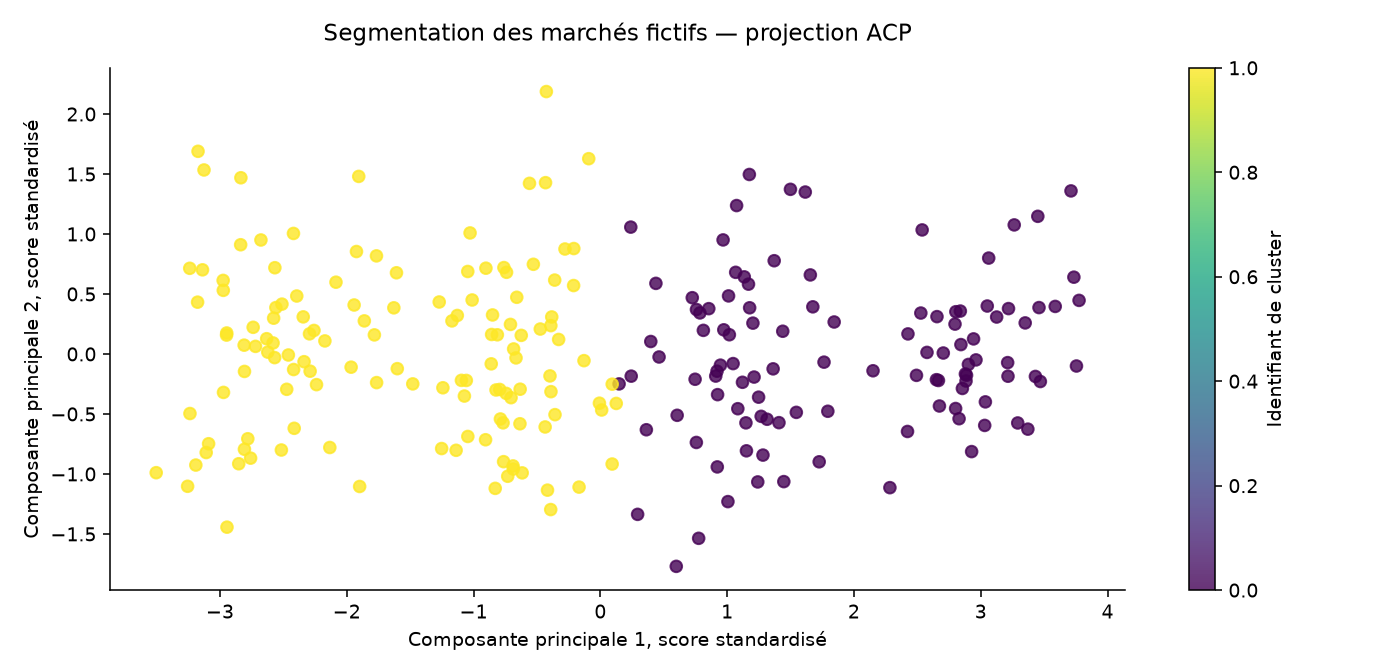

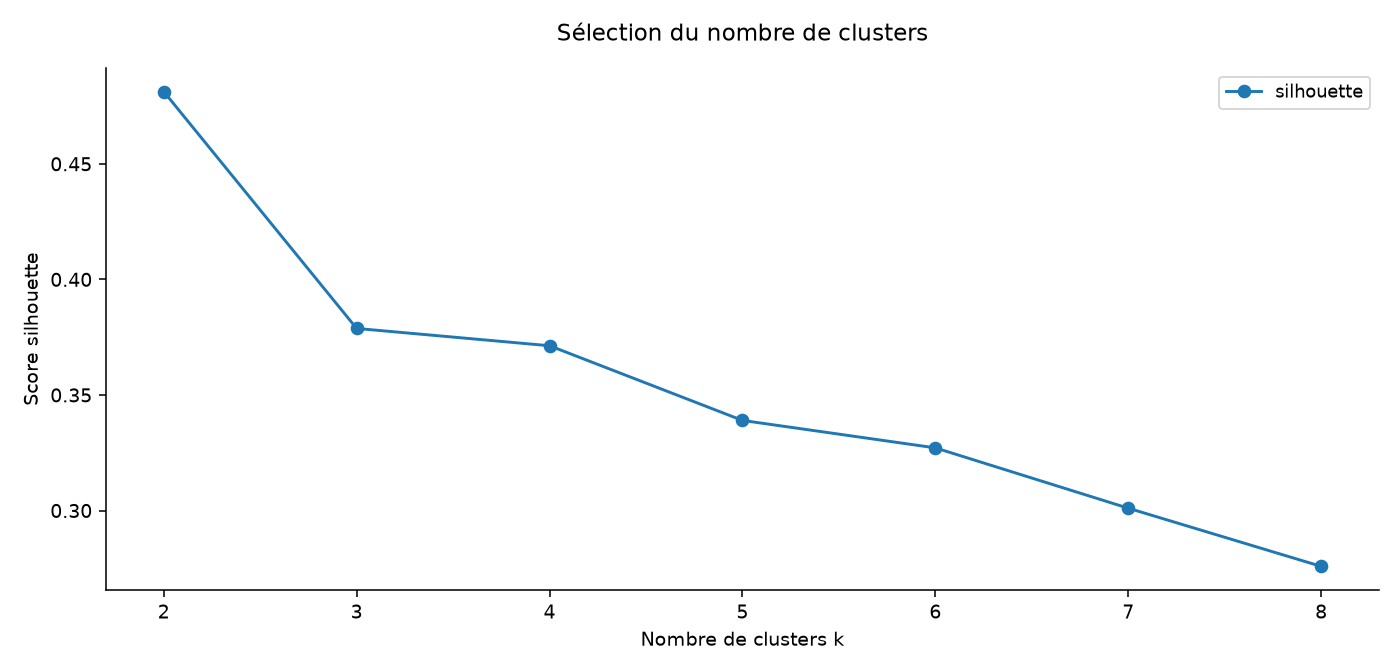

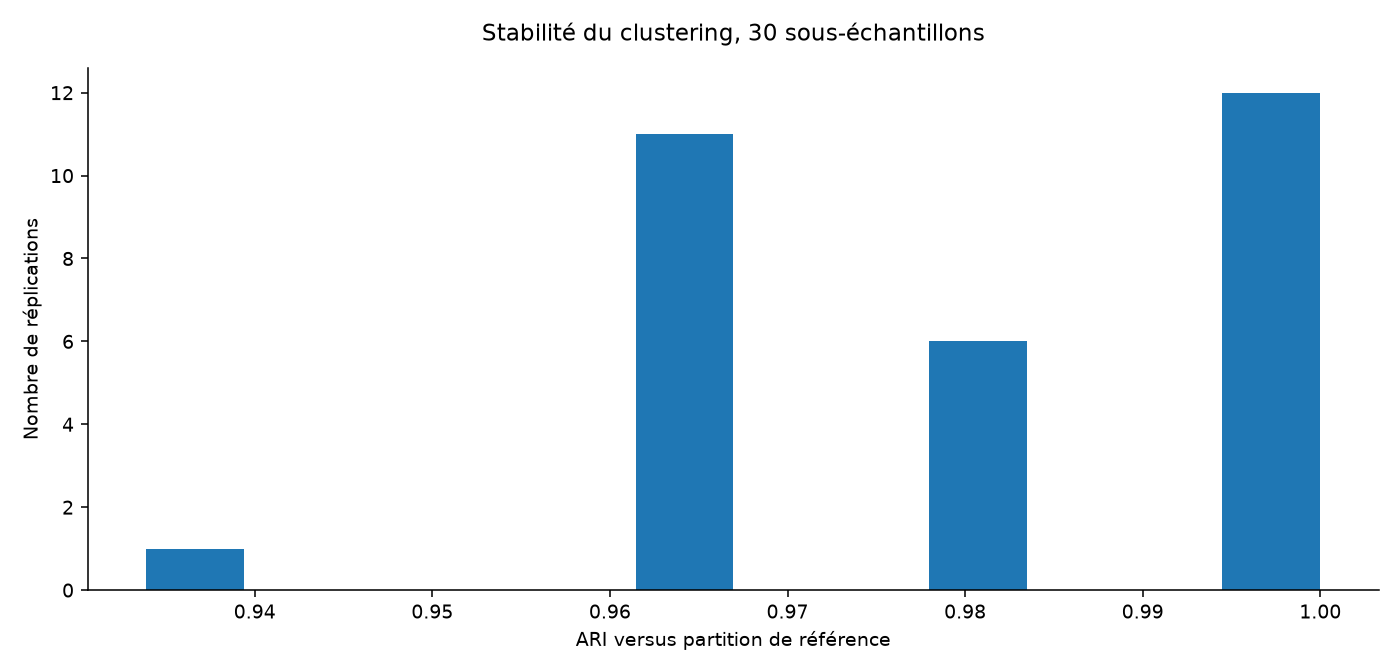

In [22]:
finish('Solaris Export — segmentation export', 'Construire des groupes comparables et vérifier la robustesse de la sélection.', {'pays': len(snapshot), 'k_retenu': k, 'silhouette': scores.silhouette.max(), 'variance_pc1_pc2': pca.explained_variance_ratio_[:2].sum(), 'ari_ward_kmeans': ward_ari, 'ari_stabilite_median': np.median([s['ari_sur_tous'] for s in stability]), 'ari_sans_imports': adjusted_rand_score(labels, lsmall)}, {'choix_k': scores, 'profils_clusters': profiles, 'affectations': snapshot, 'charges_acp': loadings, 'stabilite': pd.DataFrame(stability), 'shortlist': rank.head(25)}, [f'K retenu entre 2 et 8 par silhouette : {k} ; comparaison Ward, ARI {ward_ari:.3f}.', f'ACP : {100 * pca.explained_variance_ratio_[:2].sum():.1f} % de variance sur deux axes ; 30 sous-échantillonnages.'], ['Croiser groupes statistiques, contraintes douanières et capacité export.', 'Examiner les changements de groupe après retrait de la variable de volume.'], ['Territoires fictifs, groupes latents programmés ; pas de validation d’opportunité réelle.', 'Clustering exploratoire sans vérité terrain ; numéros de clusters sans ordre.', 'Stabilité conditionnelle au prétraitement global fixé, pas toute l’incertitude.'])

In [23]:
import pandas as pd, numpy as np

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [24]:
r = Restitution()

In [25]:
a = r.read('analysis/affectations.csv')

In [26]:
k = r.read('analysis/choix_k.csv')

In [27]:
s = r.read('analysis/stabilite.csv')

In [28]:
c = r.read('analysis/charges_acp.csv')

In [29]:
short = r.read('analysis/shortlist.csv')

In [30]:
m = r.m

In [31]:
profiles = a.groupby('cluster').agg(marches=('pays_id', 'size'), pib_median=('pib_habitant', 'median'), equipement_median=('equipements_par_1000', 'median'), imports_medians=('importations_unites', 'median'), risque_median=('risque_logistique', 'median'), croissance_mediane=('croissance_pct', 'median')).reset_index()

In [32]:
r.resume = [f'Solaris Export compare {len(a)} marchés fictifs à partir de cinq variables moyennées sur 2022–2024.', f"La silhouette retient {m['k_retenu']} groupes : {m['silhouette']:.3f}. Les deux premiers axes expliquent {m['variance_pc1_pc2']:.1%} de la variance.", f"La stabilité médiane par sous-échantillonnage est de {m['ari_stabilite_median']:.3f}. La liste commerciale de 25 marchés relève d’un score distinct du clustering."]

In [33]:
r.section('4. Construire des marchés comparables', ['L’unité de comparaison est le marché, et non chaque observation annuelle. La moyenne 2022–2024 réduit le bruit annuel mais masque une partie des ruptures récentes. Les années antérieures restent dans les données sources pour permettre des approfondissements.', 'Le PIB et les importations sont transformés par log(1+x), puis les valeurs absentes sont imputées par médiane et les cinq variables standardisées. Sans standardisation, les volumes importés domineraient les distances. Ces opérations sont ajustées sur le panel exploratoire complet : aucun score prédictif hors échantillon n’est revendiqué.', 'Le niveau d’équipement est exprimé pour 1 000 habitants, les importations en unités annuelles et le risque sur une échelle de 0 à 100. Une population élevée peut accroître les volumes sans signifier un meilleur potentiel individuel.'])

## 4. Construire des marchés comparables

L’unité de comparaison est le marché, et non chaque observation annuelle. La moyenne 2022–2024 réduit le bruit annuel mais masque une partie des ruptures récentes. Les années antérieures restent dans les données sources pour permettre des approfondissements.

Le PIB et les importations sont transformés par log(1+x), puis les valeurs absentes sont imputées par médiane et les cinq variables standardisées. Sans standardisation, les volumes importés domineraient les distances. Ces opérations sont ajustées sur le panel exploratoire complet : aucun score prédictif hors échantillon n’est revendiqué.

Le niveau d’équipement est exprimé pour 1 000 habitants, les importations en unités annuelles et le risque sur une échelle de 0 à 100. Une population élevée peut accroître les volumes sans signifier un meilleur potentiel individuel.

In [34]:
r.section('5. Choisir le nombre de groupes', [f"Sept partitions, de deux à huit groupes, sont comparées. Le maximum de silhouette est {m['silhouette']:.3f} pour k={m['k_retenu']}. Ce critère arbitre compacité et séparation ; il ne garantit pas une segmentation commerciale optimale.", 'L’inertie baisse mécaniquement lorsque k augmente. Elle doit être lue avec la silhouette, les tailles de groupes et l’utilité métier. Les numéros de groupes sont des étiquettes arbitraires ; un groupe 1 n’est pas meilleur qu’un groupe 0.'], [('Comparaison des partitions', k), ('Profils économiques des groupes', profiles)])

## 5. Choisir le nombre de groupes

Sept partitions, de deux à huit groupes, sont comparées. Le maximum de silhouette est 0.481 pour k=2. Ce critère arbitre compacité et séparation ; il ne garantit pas une segmentation commerciale optimale.

L’inertie baisse mécaniquement lorsque k augmente. Elle doit être lue avec la silhouette, les tailles de groupes et l’utilité métier. Les numéros de groupes sont des étiquettes arbitraires ; un groupe 1 n’est pas meilleur qu’un groupe 0.

### Comparaison des partitions

   k  silhouette     inertie
0  2    0.481248  474.240993
1  3    0.378774  333.921990
2  4    0.371293  253.275096
3  5    0.338988  226.106195
4  6    0.327113  203.614162
5  7    0.301018  184.681615
6  8    0.275854  169.456776

### Profils économiques des groupes

   cluster  marches    pib_median  equipement_median  imports_medians  \
0        0      108  13219.473490          25.372067    129568.227150   
1        1      131   6288.830886          15.638858     21193.095715   

   risque_median  croissance_mediane  
0      46.758291            2.917829  
1      73.337267            1.490931  

In [35]:
r.section('6. Interpréter la projection ACP', [f"La projection sur deux axes conserve {m['variance_pc1_pc2']:.1%} de la variance standardisée. La part restante impose de vérifier les distances dans les cinq dimensions avant d’interpréter deux points voisins sur le graphique.", 'Les coefficients présentés sont les composantes de l’ACP, et non directement des corrélations variable-axe. Leur signe peut s’inverser sans modifier la projection. Les profils en unités originales servent à donner un sens métier aux groupes.'], [('Coefficients des composantes principales', c)])

## 6. Interpréter la projection ACP

La projection sur deux axes conserve 91.2% de la variance standardisée. La part restante impose de vérifier les distances dans les cinq dimensions avant d’interpréter deux points voisins sur le graphique.

Les coefficients présentés sont les composantes de l’ACP, et non directement des corrélations variable-axe. Leur signe peut s’inverser sans modifier la projection. Les profils en unités originales servent à donner un sens métier aux groupes.

### Coefficients des composantes principales

               variable       PC1       PC2       PC3       PC4       PC5
0          pib_habitant  0.477597 -0.033665 -0.304161 -0.468564  0.677276
1  equipements_par_1000  0.472326 -0.065944 -0.351101  0.803410  0.061801
2   importations_unites  0.405550 -0.610025  0.680658  0.009286 -0.004201
3     risque_logistique -0.477557  0.035469  0.315868  0.365312  0.733114
4        croissance_pct  0.395321  0.788118  0.470262  0.037955 -0.002144

In [36]:
r.section('7. Tester la robustesse', [f"La classification hiérarchique de Ward et K-means obtiennent un indice de Rand ajusté de {m['ari_ward_kmeans']:.3f}. La médiane de 30 répétitions sur 80 % des marchés atteint {s.ari_sur_tous.median():.3f}, avec un minimum de {s.ari_sur_tous.min():.3f} et un maximum de {s.ari_sur_tous.max():.3f}.", f"Après retrait des importations, l’accord vaut {m['ari_sans_imports']:.3f}. Cette sensibilité renseigne sur le poids du volume dans la segmentation. La stabilité est conditionnelle au prétraitement global fixé ; elle ne couvre pas l’incertitude liée aux sources ou aux hypothèses de génération."], [('Stabilité des trente répétitions', s)])

## 7. Tester la robustesse

La classification hiérarchique de Ward et K-means obtiennent un indice de Rand ajusté de 0.967. La médiane de 30 répétitions sur 80 % des marchés atteint 0.983, avec un minimum de 0.934 et un maximum de 1.000.

Après retrait des importations, l’accord vaut 0.950. Cette sensibilité renseigne sur le poids du volume dans la segmentation. La stabilité est conditionnelle au prétraitement global fixé ; elle ne couvre pas l’incertitude liée aux sources ou aux hypothèses de génération.

### Stabilité des trente répétitions

    iteration  ari_sur_tous
0           0      1.000000
1           1      0.966666
2           2      0.966666
3           3      1.000000
4           4      1.000000
5           5      0.966666
6           6      0.966666
7           7      0.983263
8           8      1.000000
9           9      0.966666
10         10      1.000000
11         11      0.983263
12         12      0.966666
13         13      1.000000
14         14      0.983263
15         15      1.000000
16         16      1.000000
17         17      0.983263
18         18      0.966666
19         19      1.000000
20         20      1.000000
21         21      0.966666
22         22      1.000000
23         23      0.983263
24         24      0.933898
25         25      0.966666
26         26      0.966666
27         27      0.983263
28         28      1.000000
29         29      0.966666

In [37]:
r.section('8. Transformer la segmentation en investigation commerciale', ['Le score de présélection combine 45 % de rang de PIB par habitant, 35 % de rang d’équipement et 20 % de rang inversé de risque logistique. Ces pondérations sont des préférences explicites, pas des coefficients appris. Elles favorisent les marchés déjà équipés et doivent être contestées si l’entreprise recherche plutôt des marchés émergents.', 'Les 25 premiers marchés forment un panel de vérification. Aucun chiffre d’affaires potentiel n’est estimé : prix, concurrents, droits de douane, certifications et réseau de distribution sont absents. Le regroupement aide à différencier les questions à poser, sans remplacer cette enquête.'], [('Présélection commerciale à vérifier', short)])

## 8. Transformer la segmentation en investigation commerciale

Le score de présélection combine 45 % de rang de PIB par habitant, 35 % de rang d’équipement et 20 % de rang inversé de risque logistique. Ces pondérations sont des préférences explicites, pas des coefficients appris. Elles favorisent les marchés déjà équipés et doivent être contestées si l’entreprise recherche plutôt des marchés émergents.

Les 25 premiers marchés forment un panel de vérification. Aucun chiffre d’affaires potentiel n’est estimé : prix, concurrents, droits de douane, certifications et réseau de distribution sont absents. Le regroupement aide à différencier les questions à poser, sans remplacer cette enquête.

### Présélection commerciale à vérifier

    pays_id  pib_habitant  equipements_par_1000  importations_unites  \
0        95  21561.068000             33.483961        325960.412258   
1         1  22510.108383             31.927793        177253.923658   
2       165  20149.973839             32.911178        231854.823685   
3        93  21133.314360             29.757090         75817.868063   
4       236  20803.083175             30.627640        320761.491067   
5        61  21083.696382             28.939554        338086.328256   
6        36  19932.529786             29.770413        157189.797170   
7       148  21554.452235             28.649594         69588.437022   
8        71  23762.335914             27.638996        126563.424094   
9       140  20667.996088             29.616145        164922.832583   
10      208  19480.695740             31.473692        328827.306212   
11      139  17178.917444             32.773770        118112.869596   
12      225  16753.744265             33.018833        167353.68

In [38]:
r.actions = [['1', 'Contrôler les sources', 'Valider unités et fraîcheur avec le responsable études', 'Aucun indicateur ambigu'], ['2', 'Comparer les groupes', 'Examiner les profils en unités originales', 'Segmentation interprétable'], ['3', 'Contester les poids', 'Tester plusieurs préférences commerciales', 'Liste des marchés sensibles'], ['4', 'Enquêter sur le terrain', 'Vérifier concurrence, réglementation et coûts', 'Décision documentée']]

In [39]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

Solaris Export compare 239 marchés fictifs à partir de cinq variables moyennées sur 2022–2024.

La silhouette retient 2 groupes : 0.481. Les deux premiers axes expliquent 91.2% de la variance.

La stabilité médiane par sous-échantillonnage est de 0.983. La liste commerciale de 25 marchés relève d’un score distinct du clustering.

   0                        1  \
0  1    Contrôler les sources   
1  2     Comparer les groupes   
2  3      Contester les poids   
3  4  Enquêter sur le terrain   

                                                   2  \
0  Valider unités et fraîcheur avec le responsabl...   
1          Examiner les profils en unités originales   
2          Tester plusieurs préférences commerciales   
3      Vérifier concurrence, réglementation et coûts   

                             3  
0      Aucun indicateur ambigu  
1   Segmentation interprétable  
2  Liste des marchés sensibles  
3          Décision documentée  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [40]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
